从0开始进行的一次深度学习小实验

## 1. 实验概述

本实验**不调用任何深度学习框架**（PyTorch / TensorFlow / Keras 都不用），只用 `numpy` 从零实现一个**两层全连接神经网络**，完成手写数字识别任务。

你会亲手实现并理解以下核心机制：

1. **前向传播**：数据如何一层层流过网络变成预测；
2. **激活函数**：sigmoid / softmax 的作用；
3. **损失函数**：交叉熵如何衡量"预测有多差"；
4. **反向传播**：如何用链式法则高效算出每个参数的梯度（并**用数值梯度验证它写对了**）；
5. **小批量随机梯度下降（mini-batch SGD）**：如何用梯度把损失一点点压下去。

除了文字和代码，本实验还会把整个过程画出来，你会看到：**网络结构图、激活函数曲线、交叉熵损失曲线、训练学习曲线、测试集预测、混淆矩阵、第一层学到的权重模式**——把"黑盒"拆开看。

数据使用 scikit-learn 内置的手写数字集（8×8 像素，共 1797 张），它是 MNIST（28×28、7 万张）的"缩小版"，秒级训练、无需联网下载，代码可以直接迁移到 MNIST。

读的时候可以带着 5 个问题走：数据长什么样？网络怎么把 64 个像素变成 10 个概率？猜得有多差怎么量化？错了该往哪个方向改？改多少遍才够？——正好对应下面第 2~9 节。

**人话版预告**：我们要训练一个"看图猜数字"的新手。它一开始完全没经验，只能在 0~9 里瞎猜（每个数字各 10% 概率）；我们用带答案的图让它一遍遍猜、猜错就"扣分并吸取教训"，直到它看到从没见过的图也能猜对 92%。

In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# Windows 下指定中文字体，避免图表里的中文显示成方块
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

print("numpy      :", np.__version__)
print("matplotlib :", matplotlib.__version__)

numpy      : 2.4.6
matplotlib : 3.11.2


## 2. 数据准备：手写数字数据集

`load_digits` 返回 1797 张 8×8 像素的**手写数字图片**，图片画的就是阿拉伯数字 0~9，所以标签 `y` 记录的是"这张图写的是哪个数字"。

- `X`：每张图被拉平成 64 维向量（8×8 的像素逐行展开），形状 (1797, 64)，是模型的**输入特征**；
- `y`：每张图的标签（0~9），形状 (1797,)，是模型要**预测的目标**。

**归一化**：像素取值 0~16，把范围缩放到 [0, 1]。如果数值太大，矩阵乘出来的数会很大，sigmoid 会被压到饱和区、梯度几乎为 0，网络学不动。

可以把 X 看成"作业题目"（像素），把 y 看成"标准答案"（数字）。训练集是"带答案的练习册"，测试集是"期末考卷"——练习册上改错再多也不算数，考卷上的分数才算真本事。

In [2]:
from sklearn.datasets import load_digits

digits = load_digits()
X = digits.data       # (1797, 64)  每行是一张 8x8 图像拉平后的 64 个像素
y = digits.target     # (1797,)     标签 0~9（一维数组）

# 归一化：原始像素范围 [0, 16] -> [0, 1]
X = X / 16.0

print("样本数:", X.shape[0], "| 特征数(像素):", X.shape[1], "| 类别数:", len(np.unique(y)))
print("各类别样本数:", np.bincount(y).tolist())   # 依次对应 0~9 各有多少张图

样本数: 1797 | 特征数(像素): 64 | 类别数: 10
各类别样本数: [178, 182, 177, 183, 181, 182, 181, 179, 174, 180]


先直观地看一眼数据长什么样。

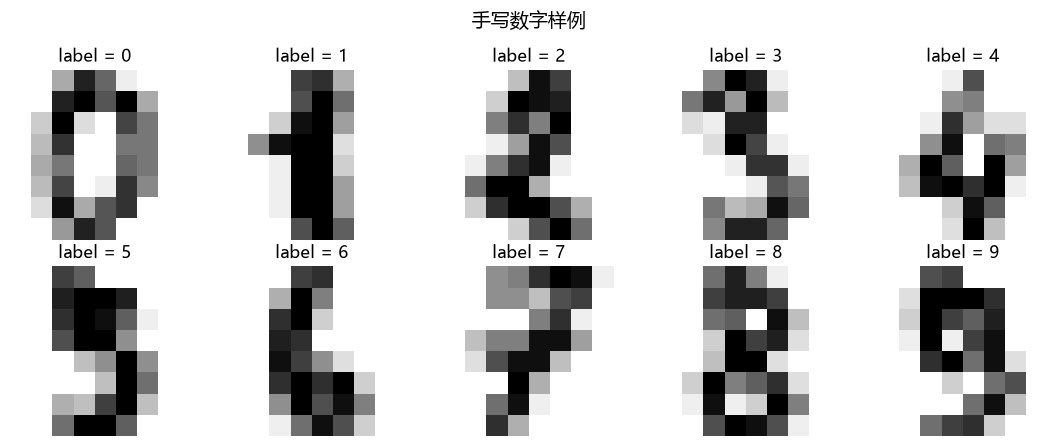

In [3]:
# 可视化数据：直观看看手写数字长什么样
fig, axes = plt.subplots(2, 5, figsize=(11, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"label = {y[i]}")
    ax.axis("off")
plt.suptitle("手写数字样例", fontsize=14)
plt.tight_layout()
plt.show()

## 3. 划分数据集与 one-hot 标签

**训练 / 测试划分（约 6:1）**：测试集从头到尾不参与训练，只用来检验"没见过的数据"上表现如何（防止只记住训练数据）。原始数据按 0,1,2,…9 顺序排列，所以要先**打乱再切**，避免训练集缺某类数字。

**one-hot（独热）标签**：交叉熵损失需要"概率形式"的标签。对 10 分类，给每个类别分配一个长度 10 的向量，**只有对应类别的位置填 1，其余全部为 0**。例如整数 3 → `[0,0,0,1,0,0,0,0,0,0]`（第 3 位，从 0 开始计数）。

为什么不能直接用整数 3 当标签？两个原因：
1. 整数自带"大小"含义：如果标签是 0,1,2,…9，模型会误以为类别之间有 3 > 1 的大小关系——但数字 3 和数字 1 只是**不同类别**，没有大小可言。one-hot 把标签变成只有 0 和 1，消除这种误导；
2. 形状匹配：网络输出是 (样本数, 10) 的概率矩阵，one-hot 标签也是 (样本数, 10)，两者才能逐元素算交叉熵。

可以把 one-hot 理解成 10 个开关：真实是几就只拨亮几号开关。数字 3 → 只有第 3 个开关亮，其他全灭（`[0,0,0,1,0,0,0,0,0,0]`）。为什么不能直接用整数 3？因为"3"看起来比"1"大，模型会误以为类别有大小关系——可"数字 3"和"数字 1"只是两种不同的字，没有 3 > 1 这回事。

In [4]:
# 固定随机种子：保证每次运行打乱顺序一样，结果可复现
np.random.seed(0)
idx = np.random.permutation(X.shape[0])     # 把 0~1796 的样本编号随机打乱

n_train = int(X.shape[0] * 6 / 7)           # 约 6/7 做训练（1540 张），1/7 做测试（257 张）
train_idx, test_idx = idx[:n_train], idx[n_train:]   # 前 1540 个编号训练，其余测试

# 用同一套索引切 X 和 y，保证图片和它的标签不错位
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

def one_hot(y, num_classes=10):
    """整数标签 -> one-hot 矩阵"""
    t = np.zeros((y.size, num_classes))     # 全 0 矩阵：行 = 样本数，列 = 10
    t[np.arange(y.size), y] = 1             # 每行在标签 y 对应的列位置填 1
    return t

T_train = one_hot(y_train)                  # 训练集 one-hot 标签 (1540, 10)
T_test = one_hot(y_test)                    # 测试集 one-hot 标签 (257, 10)
print("训练集:", X_train.shape, "| 测试集:", X_test.shape)

训练集: (1540, 64) | 测试集: (257, 64)


## 4. 核心组件①：激活函数

### sigmoid
$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

作用：把任意一个实数压到 **(0, 1)** 之间。
- $z=100$ → 输出接近 1；$z=0$ → 输出 0.5；$z=-100$ → 输出接近 0。

它给网络带来**非线性**：如果没有激活函数，每一层都只是"输出 = W×输入 + b"的线性运算，多层线性叠起来仍等价于一层线性，堆多少层也只能画一条直线、学不了复杂图案。sigmoid 这种非线性函数插在层与层之间，网络才能画出弯弯扭扭的分界线，识别手写数字这类非线性图案。


它一般出现在两个位置：
- **二分类的输出层**：只有 2 种结果（是 / 不是），网络最后输出 1 个数，丢进 sigmoid 得到 0~1 当作概率，接近 1 是、接近 0 不是；
- **隐藏层**：咱们的 10 分类任务，输出层不能再用 sigmoid（要用 softmax），但**中间隐藏层**可以放 sigmoid——隐藏层的任务不是输出概率，只是提供非线性能力。

### softmax（10 分类任务的输出激活函数）
$$\mathrm{softmax}(a)_k = \frac{e^{a_k}}{\sum_j e^{a_j}}$$

作用：把一组数字（logits）变成**总和 = 1 的概率分布**。咱们网络最后一层输出 10 个数（对应数字 0~9，叫 logits），softmax 把它们变成 10 个概率：哪个位置数字最大，对应概率最高，代表模型认为图片最有可能是这个数字。

例子：logits = `[2, 5, 1, 0, 0, 0, 0, 0, 0, 0]` → softmax 后第 1 个位置（数字 1）概率最大，10 个数相加 = 1。

**数值稳定技巧**：如果 $a_k$ 很大，$e^{a_k}$ 会溢出成 `inf` 导致计算出错。解决办法是先让每行减去自己的最大值再取指数：$e^{a_k - \max a}$。因为分子分母同乘 $e^{-\max a}$，结果数学上完全不变，只是指数不会爆炸。自己实现 softmax 时这一步**不能省**。

In [5]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

def softmax(a):
    # 每行减去最大值，保证数值稳定（不改变概率结果）
    a = a - np.max(a, axis=1, keepdims=True)
    exp_a = np.exp(a)
    return exp_a / np.sum(exp_a, axis=1, keepdims=True)

# 自测
z = np.array([[0.5, -1.0, 2.0]])
print("sigmoid:", sigmoid(z))
print("softmax 每行和为 1:", softmax(z).sum(axis=1))

sigmoid: [[0.62245933 0.26894142 0.88079708]]
softmax 每行和为 1: [1.]


把 sigmoid 和它的导数画出来，直观理解"为什么两端梯度会消失"。

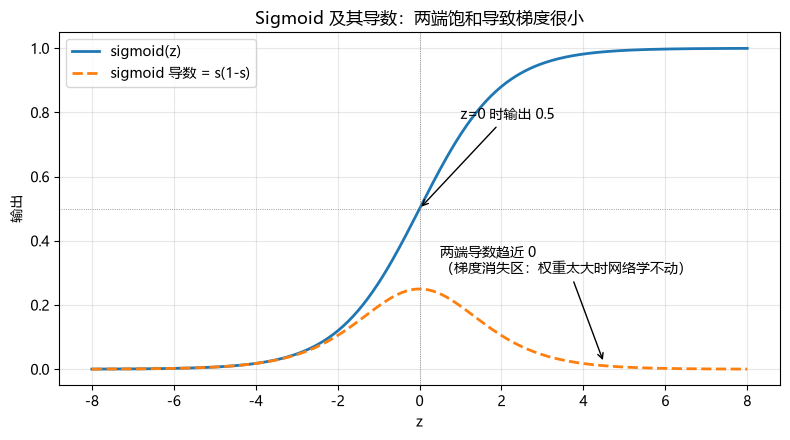

In [6]:
z = np.linspace(-8, 8, 400)
s = sigmoid(z)
ds = s * (1 - s)                 # sigmoid 的导数 = s(1-s)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(z, s, lw=2, label="sigmoid(z)")
ax.plot(z, ds, lw=2, ls="--", label="sigmoid 导数 = s(1-s)")
ax.axhline(0.5, color="gray", lw=0.6, ls=":")
ax.axvline(0, color="gray", lw=0.6, ls=":")
ax.annotate("z=0 时输出 0.5", xy=(0, 0.5), xytext=(1.0, 0.78),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.annotate("两端导数趋近 0\n（梯度消失区：权重太大时网络学不动）",
            xy=(4.5, 0.02), xytext=(0.5, 0.30),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.set_xlabel("z"); ax.set_ylabel("输出")
ax.set_title("Sigmoid 及其导数：两端饱和导致梯度很小")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. 核心组件②：交叉熵损失

对单个样本，交叉熵衡量"预测分布 $y$ 和真实分布 $t$ 有多不一致"：
$$L = -\sum_{k=0}^{9} t_k \ln y_k$$

符号说明：
- $t$：真实标签的 one-hot 向量（比如数字 3 → `[0,0,0,1,0,...]`）；
- $y_k$：模型 softmax 输出，认为该样本属于类别 $k$ 的概率；
- $\sum_{k=0}^9$：把 10 个类别全部相加；负号保证损失永远为正。

因为 one-hot 只有真实类别那一位是 1，其余都是 0，求和之后只剩下真实类别那一项，所以 $L = -\ln(y_{\text{true}})$。例子：真实是 3，
$$L = -\big(0\cdot\ln y_0 + \cdots + 1\cdot\ln y_3 + \cdots\big) = -\ln y_3$$

- 模型预测 $y_3=1$（完美猜对）→ $-\ln 1 = 0$，损失 0；
- 模型预测 $y_3=0.1$（基本瞎猜）→ $-\ln 0.1 \approx 2.302$，损失很大。

一个容易绕晕的点，帮你想清楚：**"预测概率接近 1"是模型的"确信度"，而"损失"是"扣分"**——一个是得分、一个是扣分，方向相反。完全正确 = 没有错误 = 扣 0 分 = 损失 0。所以"越接近 1 损失越小，猜对了损失是 0 而不是 1"。

再换一个说法：把它想成猜数字游戏。你押 100% 是 3，答案真是 3，罚 0 分；你只敢押 10% 是 3，答案真是 3，罚约 2.3 分；你几乎没押它，罚得更狠。押得越不准，罚得越狠。

为什么要用它而不是简单的"1 - 概率"？因为对数会**狠狠惩罚完全猜错**的情况：概率从 0.01 提到 0.1，损失掉一大截；从 0.9 提到 0.99，损失只掉一点点。这种特性让训练时错得越狠、改得越猛，收敛更快；而且它和 softmax 组合后梯度形式极简（后面会看到 $y-t$）。



另外两个实现细节：
- 数值上给 $\ln$ 加一个极小量 $\delta=10^{-7}$，防止概率为 0 时 $\ln 0$ 崩溃成负无穷；
- 批量训练时取**所有样本损失的平均值**（除以样本数）。

In [7]:
def cross_entropy(y_pred, t):
    """y_pred: (N, K) 预测概率;  t: (N, K) one-hot 标签"""
    delta = 1e-7                       # 防止 log(0)
    return -np.sum(t * np.log(y_pred + delta)) / y_pred.shape[0]

# 自测：均匀预测 10 类时，损失应接近 ln(10) ≈ 2.3026
fake = np.full((1, 10), 0.1)
t = one_hot(np.array([3]))
print("均匀预测的损失:", cross_entropy(fake, t))

均匀预测的损失: 2.302584092994546


把 $L = -\ln(y_{true})$ 画出来，直观看到"越接近 1 损失越小、接近 0 惩罚越狠"。

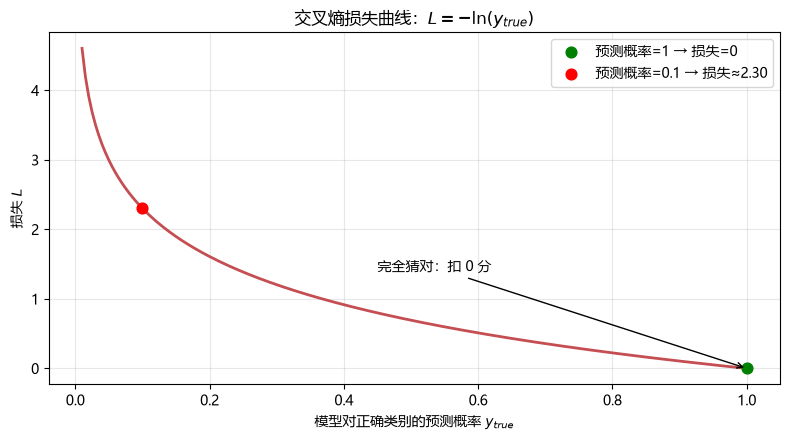

In [8]:
p = np.linspace(0.01, 1.0, 200)
L = -np.log(p)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(p, L, lw=2, color="#C44E52")
ax.scatter([1.0], [0.0], color="green", zorder=3, s=60, label="预测概率=1 → 损失=0")
ax.scatter([0.1], [np.log(10)], color="red", zorder=3, s=60, label="预测概率=0.1 → 损失≈2.30")
ax.annotate("完全猜对：扣 0 分", xy=(1.0, 0.0), xytext=(0.45, 1.4),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.set_xlabel("模型对正确类别的预测概率 $y_{true}$")
ax.set_ylabel("损失 $L$")
ax.set_title("交叉熵损失曲线：$L=-\ln(y_{true})$")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. 两层神经网络：结构与前向传播

网络结构：**输入层 64 → 隐藏层 50（sigmoid）→ 输出层 10（softmax）**。这是一个"两层计算层"的网络（输入层只负责传数据，不算计算层）。

对应咱们的手写数字任务：
- **输入层 64**：每张手写图是 8×8=64 个像素，拉平成 64 个数，是网络的输入；
- **隐藏层 50**：中间 50 个神经元，负责从像素里提取特征（横线、竖线、小圈圈等），用 sigmoid 提供非线性；
- **输出层 10**：对应数字 0~9，用 softmax 输出"这张图是每个数字的概率"。

**前向传播**就是数据从左到右的计算流程，两个矩阵乘法加两个激活：
$$h = \sigma(x W_1 + b_1), \qquad y = \mathrm{softmax}(h W_2 + b_2)$$

逐步拆解（注意每一步的形状变化）：
1. `x`：输入，形状 `(N, 64)`，N 张图片；
2. `xW₁ + b₁`：第一层线性变换。$W_1$ 形状 `(64, 50)`，结果 `(N, 50)`，再加长度 50 的偏置 $b_1$；
3. `σ(...)`：套 sigmoid，得到隐藏层输出 `h`，形状 `(N, 50)`；
4. `hW₂ + b₂`：第二层线性变换。$W_2$ 形状 `(50, 10)`，结果 `(N, 10)`，加长度 10 的偏置 $b_2$；
5. `softmax(...)`：转成 10 个加起来等于 1 的概率，形状 `(N, 10)`，就是预测结果。

数据形状流转可以这样看：
```
x (N,64) →  ×W1(64,50)+b1(50) →  z1 (N,50) →  σ →  h (N,50)
        →  ×W2(50,10)+b2(10) →  z2 (N,10) →  softmax →  y (N,10)
```
一句话：**两次矩阵乘法 + 两次激活函数，把 64 个像素变成 10 个数字的概率**。

可以把网络想成一条流水线：输入层是进料口（64 个像素进厂）；隐藏层是第一个车间（50 台机器各认一种笔画：横线、竖线、圈……sigmoid 让机器有"手感"）；输出层是质检台（对 10 个类别各打一个分）；softmax 把分数变成最终报告（概率）。前向传播就是原料从左到右走完这条流水线。

**网络要学的 4 个参数**：$W_1$ (64×50)、$b_1$ (50)、$W_2$ (50×10)、$b_2$ (10)。训练的目标就是不断调整它们，让交叉熵损失越来越小。

**为什么权重必须随机初始化（打破对称性）**：如果所有权重初始化为 0，同一层所有神经元的输入、输出、梯度完全相同，每次更新都改得一模一样——相当于这一层只有 1 个神经元在工作，学不出复杂特征。所以权重必须用小的随机数，让每个神经元起点不同、各学各的特征；偏置初始化为 0 没关系（权重已随机，不再对称）。

**标准差取 $1/\sqrt{64}$（Xavier 初始化的思路）**：让信号在层间传播时方差保持稳定，不大不小。
- 权重太大：矩阵乘完数值很大，sigmoid 被压到接近 0 或 1 的平坦区，导数接近 0（梯度消失），网络学不动、训练震荡；
- 权重太小（比如 0.01）：sigmoid 输出全挤在 0.5 附近，梯度也极小，学习极慢。咱们实验里就是这么现象的：标准差 0.01 训 60 轮精度只有 77.8%，换成 0.125 同样的 60 轮能到 92.2%。

这里重点是理解思路：代码只是把上面的公式逐行翻译成 numpy。

为什么不能全 0 初始化？全 0 等于所有机器出厂设置一模一样，学来学去还是一模一样，等于只有 1 台机器在干活。

把网络结构画出来，看清"全连接"长什么样。

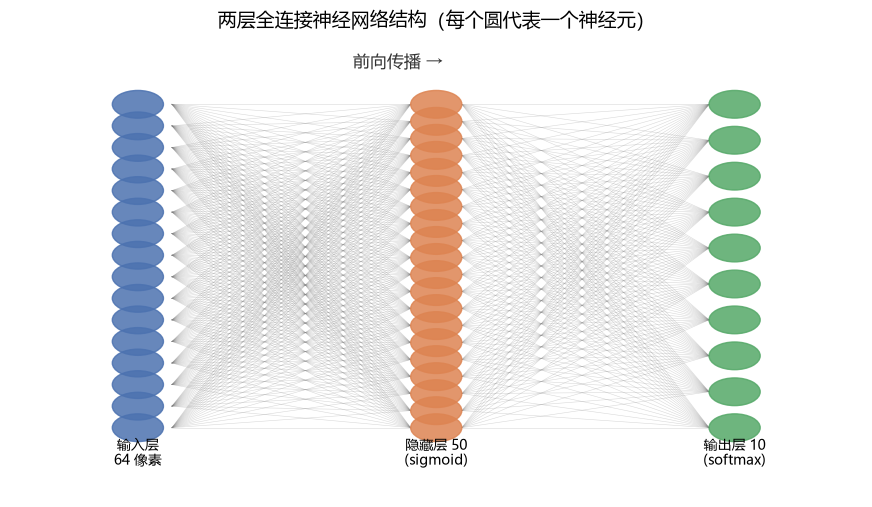

In [9]:
fig, ax = plt.subplots(figsize=(11, 6))
ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis("off")

def draw_layer(x, n, label, color):
    ys = np.linspace(1.5, 8.5, n)
    for y in ys:
        ax.add_patch(plt.Circle((x, y), 0.30, color=color, alpha=0.85, zorder=2))
    ax.text(x, 0.7, label, ha="center", fontsize=10)
    return ys

ys_in = draw_layer(1.5, 16, "输入层\n64 像素", "#4C72B0")
ys_h  = draw_layer(5.0, 20, "隐藏层 50\n(sigmoid)", "#DD8452")
ys_o  = draw_layer(8.5, 10, "输出层 10\n(softmax)", "#55A868")

# 相邻层全连接示意（每条细线代表一个连接）
for yi in ys_in:
    for yh in ys_h:
        ax.plot([1.9, 4.7], [yi, yh], color="gray", lw=0.4, alpha=0.30, zorder=1)
for yh in ys_h:
    for yo in ys_o:
        ax.plot([5.3, 8.2], [yh, yo], color="gray", lw=0.4, alpha=0.30, zorder=1)

ax.annotate("前向传播 →", xy=(4.55, 9.3), fontsize=12, ha="center", color="#333333")
plt.title("两层全连接神经网络结构（每个圆代表一个神经元）", fontsize=14)
plt.show()

In [10]:
class TwoLayerNet:
    def __init__(self, input_size, hidden_size, output_size, weight_init_std=None):
        # Xavier 初始化的思路：标准差 = 1/sqrt(输入维度)
        if weight_init_std is None:
            weight_init_std = 1.0 / np.sqrt(input_size)
        self.params = {
            "W1": weight_init_std * np.random.randn(input_size, hidden_size),
            "b1": np.zeros(hidden_size),
            "W2": weight_init_std * np.random.randn(hidden_size, output_size),
            "b2": np.zeros(output_size),
        }

    def forward(self, x):
        """前向传播，返回每个类别的预测概率"""
        W1, b1 = self.params["W1"], self.params["b1"]
        W2, b2 = self.params["W2"], self.params["b2"]
        h = sigmoid(np.dot(x, W1) + b1)      # 隐藏层
        y = softmax(np.dot(h, W2) + b2)      # 输出层概率
        return y

    def predict(self, x):
        return np.argmax(self.forward(x), axis=1)

    def accuracy(self, x, t):
        return np.mean(self.predict(x) == np.argmax(t, axis=1))

np.random.seed(0)
net = TwoLayerNet(input_size=64, hidden_size=50, output_size=10)
# 训练前两个 sanity check：损失应接近 ln(10)≈2.30（输出近似均匀分布），精度应很低（还没学）
print("初始化后训练集精度: %.4f" % net.accuracy(X_train[:200], T_train[:200]))
print("初始化后损失       : %.4f (应接近 2.30)" % cross_entropy(net.forward(X_train[:200]), T_train[:200]))

初始化后训练集精度: 0.0900
初始化后损失       : 2.3561 (应接近 2.30)


## 7. 反向传播：解析梯度

目标：算出损失 $L$ 对每个参数 $(W_1, b_1, W_2, b_2)$ 的偏导，才能做梯度下降。直接逐个求偏导很繁琐，**反向传播（backpropagation）**用链式法则把误差从输出层"传"回输入层，计算量只比前向传播多一点。这里的链式法则就是高中学的那个求导链式法则：复合函数的导数 = 外层导数 × 内层导数。

先把它做的事用大白话说一遍：① 前向跑一遍，得到预测 $y$ 和损失 $L$；② 从输出层开始算"误差信号" $\delta_2 = y - t$（猜的和真的差多少）；③ 把误差信号按 $W_2$ 的强度回传给隐藏层，再乘上 sigmoid 的导数 $\sigma'(z_1)$——某个神经元的导数小，说明它已经"饱和"（输出太靠近 0 或 1），传给它的改动也要跟着小；④ 最后用"传回来的误差 × 这一层的输入/输出"算出每个参数的梯度。

后一层的误差是前一层的"乘数"，这就是链式法则的全部秘密：梯度 = 前面传下来的误差 × 这一步的传递率。

记隐藏层输入 $z_1 = xW_1 + b_1$、输出层输入 $z_2 = hW_2 + b_2$。

**关键结论 1（输出层）**：softmax + 交叉熵组合时，梯度有个极简形式（这是数学化简的结果，感兴趣可以自己推导）
$$\frac{\partial L}{\partial z_2} = y - t$$
即"预测概率减去 one-hot 标签"。这是从零实现时最值得记住的式子。

**关键结论 2（隐藏层）**：误差继续回传，乘上 sigmoid 的导数 $\sigma'(z) = \sigma(z)(1-\sigma(z))$：
$$\delta_1 = (\delta_2 W_2^\top) \odot \sigma'(z_1), \qquad \delta_2 = y - t$$

**参数梯度**（对 batch 内样本取平均）：
$$\frac{\partial L}{\partial W_2} = h^\top \delta_2, \quad \frac{\partial L}{\partial b_2} = \sum_n \delta_2, \quad \frac{\partial L}{\partial W_1} = x^\top \delta_1, \quad \frac{\partial L}{\partial b_1} = \sum_n \delta_1$$

这几个梯度公式也能读出直觉：$dW_2 = h^\top \delta_2$ 里，$h$ 是隐藏层输出、$\delta_2$ 是输出层误差——某条连接的"两端信号都强"，它的梯度就大、改得就多；$dW_1$ 同理。偏置 $b$ 的梯度是误差的求和平均：偏置跟着"平均误差"走。除以 $N$ 是因为损失本身就是 batch 内的平均损失，梯度也得是平均梯度，否则更新幅度会随批量大小忽大忽小。

下面的代码每一行都对应上面一个公式，对照着看。

可以先用一个**简化小算例**感受误差是怎么"回传"的（下面用 3 类示意，真实是 10 类，原理完全一样）：
假设真实标签是第 2 类：t = [0, 1, 0]；模型输出 y = [0.2, 0.7, 0.1]。
那么 delta2 = y - t = [0.2, -0.3, 0.1]，它的含义是：
- 第 2 类（真实类）：模型只给了 0.7，比该有的 1 少了 0.3 → 押低了，要往第 2 类方向加大权重；
- 第 1 类：模型给了 0.2，比该有的 0 多了 0.2 → 押高了，要收；
- 第 3 类同理，多了 0.1。
delta2 就是"每个类别的错账金额"：哪里多给了就扣，哪里少给了就补。

这个错账金额再乘 W2 的转置"分发"回隐藏层：W2.T 的形状是 (10,50)，delta2 是 (10,)，
乘出来是 (50,)，每个隐藏神经元分到一份"责任"；再乘上 h*(1-h)（sigmoid 的导数），
意思是把责任一层一层继续往回传。

对照代码会更清楚：
- `delta2 = (y - t) / N`：就是上面那个"错账"，除以 N 是因为损失取的是平均；
- `grads["W2"] = h.T @ delta2`：维度上 h.T 是 (50,N)、delta2 是 (N,10)，乘出来 (50,10)，正好和 W2 同形状——"每条连接该改多少"；
- `grads["W1"] = x.T @ delta1`：同理，x.T (64,N) × delta1 (N,50) → (64,50)，和 W1 同形状。
记住一条规则就够了：**梯度的形状永远和参数一模一样**，更新时就按这个形状逐元素减。

可以先用一个**简化小算例**感受误差是怎么"回传"的（下面用 3 类示意，真实是 10 类，原理完全一样）：
假设真实标签是第 2 类：t = [0, 1, 0]；模型输出 y = [0.2, 0.7, 0.1]。
那么 delta2 = y - t = [0.2, -0.3, 0.1]，它的含义是：
- 第 2 类（真实类）：模型只给了 0.7，比该有的 1 少了 0.3 → 押低了，要往第 2 类方向加大权重；
- 第 1 类：模型给了 0.2，比该有的 0 多了 0.2 → 押高了，要收；
- 第 3 类同理，多了 0.1。
delta2 就是"每个类别的错账金额"：哪里多给了就扣，哪里少给了就补。

这个错账金额再乘 W2 的转置"分发"回隐藏层：W2.T 的形状是 (10,50)，delta2 是 (10,)，
乘出来是 (50,)，每个隐藏神经元分到一份"责任"；再乘上 h*(1-h)（sigmoid 的导数），
意思是把责任一层一层继续往回传。

对照代码会更清楚：
- `delta2 = (y - t) / N`：就是上面那个"错账"，除以 N 是因为损失取的是平均；
- `grads["W2"] = h.T @ delta2`：维度上 h.T 是 (50,N)、delta2 是 (N,10)，乘出来 (50,10)，正好和 W2 同形状——"每条连接该改多少"；
- `grads["W1"] = x.T @ delta1`：同理，x.T (64,N) × delta1 (N,50) → (64,50)，和 W1 同形状。
记住一条规则就够了：**梯度的形状永远和参数一模一样**，更新时就按这个形状逐元素减。

输出层的 $y - t$ 也好懂：猜的减真的。真实是 3（t 第 3 位是 1），模型却押 5（y 第 5 位最大），差值就会在 3 和 5 上都留下"要改"的记号——差得越多，改得越猛。

In [11]:
def gradient(net, x, t):
    """反向传播：返回损失对全部参数的解析梯度"""
    W1, b1 = net.params["W1"], net.params["b1"]
    W2, b2 = net.params["W2"], net.params["b2"]
    N = x.shape[0]

    # ---- 前向（保存中间量，回传时要用）----
    z1 = np.dot(x, W1) + b1            # (N, 50)
    h = sigmoid(z1)
    z2 = np.dot(h, W2) + b2            # (N, 10)
    y = softmax(z2)

    grads = {}
    # ---- 输出层：softmax+交叉熵的梯度 = y - t（除以 N 是因为损失取平均）----
    delta2 = (y - t) / N
    grads["W2"] = np.dot(h.T, delta2)
    grads["b2"] = np.dot(np.ones(N), delta2)

    # ---- 隐藏层：链式法则 × sigmoid 导数 ----
    delta1 = np.dot(delta2, W2.T) * h * (1 - h)
    grads["W1"] = np.dot(x.T, delta1)
    grads["b1"] = np.dot(np.ones(N), delta1)
    return grads

## 8. 梯度正确性检查：数值梯度 vs 反向传播

反向传播很容易写错。但有一种**绝对可靠**的对照方法：直接用导数的定义做数值梯度（中心差分）：
$$\frac{\partial L}{\partial \theta_i} \approx \frac{L(\theta + \varepsilon e_i) - L(\theta - \varepsilon e_i)}{2\varepsilon}, \qquad \varepsilon = 10^{-4}$$

中心差分为什么长这样？导数就是"斜率"：想知道参数 $\theta$ 处的斜率，就在它左右各取一个很近的点（$\theta+\varepsilon$ 和 $\theta-\varepsilon$），量这两个点的高度差，再除以水平差 $2\varepsilon$。$\varepsilon$ 取 $10^{-4}$ 是经验值——太大（比如 0.1）偏离真实斜率，太小（比如 $10^{-12}$）会被浮点数精度坑，算出来反而更不准。

它很慢（每个参数要做两次前向传播），但只依赖"损失函数能算出来"，不依赖任何推导。如果数值梯度与反向传播的结果几乎一致，就说明反向传播写对了。**这是从零实现的"守门员"：先验证，再训练。**

数值梯度就是"不信邪"的验算法：直接把参数加减 ε，实测损失斜率，再和反向传播的结果对照，几乎一样就说明写对了。它慢（每个参数要跑两遍前向），所以只用来验证这一次。这个检查以后也一直有用：如果你把网络加深一层、换成 ReLU 之类的激活函数，只要重跑一次这个对照，就能确认新的反向传播没写错——先验证，再训练，永远成立。

怎么比？逐元素的相对误差在个别分量接近 0 时会被分母放大、产生假警报。更稳的做法是看两个指标：

- **最大绝对误差**：中心差分（$\varepsilon=10^{-4}$）本身的截断误差就在 $10^{-8}$ 量级，所以绝对误差到 $10^{-7}$ 量级即属正常；
- **平均相对误差**：$\frac{\mathrm{mean}|g_{num}-g_{ana}|}{\mathrm{mean}|g_{num}|+\mathrm{mean}|g_{ana}|}$，用平均值做分母，接近 0 的分量不会捣乱，应达到 $10^{-6}$ 或更小。

导数的直观意思：**参数动一丁点，损失会跟着动多少**（也就是"斜率"）。
数值梯度不靠任何公式，直接去量这个斜率：把某个参数 w 分别加、减一个极小量 ε，看损失变化：
中心差分 = [L(w+ε) − L(w−ε)] / (2ε)。
为什么要加减各测一次？因为"加 ε 测一次"和"减 ε 测一次"的误差方向相反，取平均后互相抵消，比只测一边更准。

举个数字例子：假设某个参数当前损失 L=2.3026，取 ε=0.0001：
- 参数加 ε 后，L=2.3028；
- 参数减 ε 后，L=2.3024；
- 那么该参数梯度 ≈ (2.3028 − 2.3024) / (2×0.0001) = 2.0。
意思是：这个参数每增加 1，损失大约增加 2，所以更新时应该让它往负方向走。

误差标准怎么定的：中心差分本身的误差大约在 ε² = 1e-8 量级（截断误差），加上浮点运算的小误差，
所以**最大绝对误差到 1e-7 量级、平均相对误差到 1e-6 以下，就说明反向传播写对了**。

为什么它只用来验证、不用来训练：本网络参数一共 64×50 + 50 + 50×10 + 10 = 3270 个，
每个参数都要跑两次完整的前向传播，比反向传播慢几百倍。所以它只验一次就算完。

导数的直观意思：**参数动一丁点，损失会跟着动多少**（也就是"斜率"）。
数值梯度不靠任何公式，直接去量这个斜率：把某个参数 w 分别加、减一个极小量 ε，看损失变化：
中心差分 = [L(w+ε) − L(w−ε)] / (2ε)。
为什么要加减各测一次？因为"加 ε 测一次"和"减 ε 测一次"的误差方向相反，取平均后互相抵消，比只测一边更准。

举个数字例子：假设某个参数当前损失 L=2.3026，取 ε=0.0001：
- 参数加 ε 后，L=2.3028；
- 参数减 ε 后，L=2.3024；
- 那么该参数梯度 ≈ (2.3028 − 2.3024) / (2×0.0001) = 2.0。
意思是：这个参数每增加 1，损失大约增加 2，所以更新时应该让它往负方向走。

误差标准怎么定的：中心差分本身的误差大约在 ε² = 1e-8 量级（截断误差），加上浮点运算的小误差，
所以**最大绝对误差到 1e-7 量级、平均相对误差到 1e-6 以下，就说明反向传播写对了**。

为什么它只用来验证、不用来训练：本网络参数一共 64×50 + 50 + 50×10 + 10 = 3270 个，
每个参数都要跑两次完整的前向传播，比反向传播慢几百倍。所以它只当"守门员"，验一次就算完。

In [12]:
def numerical_gradient(net, x, t, eps=1e-4):
    """数值梯度（中心差分）：慢但可靠，仅用于验证"""
    grads = {}
    for key in ("W1", "b1", "W2", "b2"):
        param = net.params[key]
        grad = np.zeros_like(param)
        flat = param.ravel()
        for i in range(flat.size):
            orig = flat[i]
            flat[i] = orig + eps
            loss_p = cross_entropy(net.forward(x), t)
            flat[i] = orig - eps
            loss_m = cross_entropy(net.forward(x), t)
            flat[i] = orig
            grad.ravel()[i] = (loss_p - loss_m) / (2 * eps)
        grads[key] = grad
    return grads

# 用小批量（5 个样本）验证
x_batch, t_batch = X_train[:5], T_train[:5]
g_num = numerical_gradient(net, x_batch, t_batch)
g_ana = gradient(net, x_batch, t_batch)

print("数值梯度 vs 反向传播：")
for key in g_num:
    num, ana = g_num[key], g_ana[key]
    abs_diff = np.abs(num - ana)
    # 平均相对误差：用平均值做分母，避免接近 0 的分量把相对误差放大
    rel = abs_diff.mean() / (np.abs(num).mean() + np.abs(ana).mean())
    print(f"  {key}: 最大绝对误差 {abs_diff.max():.2e} | 平均相对误差 {rel:.2e}")

数值梯度 vs 反向传播：
  W1: 最大绝对误差 5.86e-08 | 平均相对误差 6.10e-07
  b1: 最大绝对误差 6.26e-08 | 平均相对误差 6.11e-07
  W2: 最大绝对误差 2.84e-07 | 平均相对误差 5.90e-07
  b2: 最大绝对误差 4.25e-07 | 平均相对误差 5.89e-07


## 9. 训练：小批量随机梯度下降（mini-batch SGD）

每个 epoch 做三件事：

1. **打乱**训练样本顺序；
2. 切成若干**小批量**（batch_size = 100）；
3. 对每个批量：前向算损失 → 反向传播算梯度 → 更新参数
$$\theta \leftarrow \theta - \eta \frac{\partial L}{\partial \theta}$$

完整过一遍所有样本 = 1 个 epoch。学习曲线怎么读？损失一路下降、精度上升后趋于平坦，说明在正常学习；损失来回震荡，多半是学习率偏大；训练精度高而测试精度明显低，是过拟合——把练习册背下来了，考卷上发挥差。

记录每个 epoch 的平均损失、训练精度与测试精度，画学习曲线。

先算一笔账：1540 张训练图、每批 100 张，所以每轮有 16 个批——也就是参数每轮被更新 16 次；60 个 epoch 总共更新约 960 次。学习率 0.1 的意思是：每次更新只朝梯度方向挪 10%，挪多了容易过冲（损失震荡），挪少了半天到不了底。

超参数：学习率 $\eta = 0.1$、隐层 50 个神经元、60 个 epoch、权重用 Xavier 初始化（$1/\sqrt{64}$）。

可以把梯度下降想成下山：损失是"海拔"，梯度是"脚下坡度"，学习率是"步子大小"。往最陡的方向迈步，海拔就降。步子太大：一步跨过谷底，在山谷两边来回弹（损失震荡）；步子太小：半天走不到底（收敛慢）。

为什么一次只看一小批：1540 份作业一次全改完再统一调太"平均"；一次只批 100 份就调一次，又快又能摸着石头过河。60 个 epoch 就是把整本练习册翻来覆去改 60 遍。

把训练的三件事落到具体数字上：
- 1540 张训练图，batch_size=100，一轮切出约 16 个批次；
- 每处理完一个批次就更新一次参数，一个 epoch 更新约 16 次；
- 60 个 epoch 一共约 960 次参数更新。每次更新损失只降一点点，但 960 次叠起来，就能从"均匀瞎猜"变成"92.2% 认对"。

更新公式 θ ← θ − η·grad 拆开看：grad 告诉"往哪个方向、改多大幅度损失才下降"，η（学习率）是"步子大小"，负号表示"往下降的方向走"。

学习率大小会有什么现象（可以自己改 lr 试试）：
- lr = 0.1（本实验）：平稳下降，60 轮收敛到 92%；
- lr = 1.0：步子太大，一步跨过头，损失上下震荡，可能永远收敛不到好位置；
- lr = 0.001：步子太小，60 轮只走了一小段路，损失还很高，精度上不去。

学习曲线怎么看：损失一直往下降，说明在学；训练精度和测试精度都往上升，说明没白学；
如果训练精度很高、测试精度却上不去，说明它把练习册"背"下来了但没真正学会（过拟合），
可以试试第 12 节里说的正则化或换小一点的模型。

把训练的三件事落到具体数字上：
- 1540 张训练图，batch_size=100，一轮切出约 16 个批次；
- 每处理完一个批次就更新一次参数，一个 epoch 更新约 16 次；
- 60 个 epoch 一共约 960 次参数更新。每次更新损失只降一点点，但 960 次叠起来，就能从"均匀瞎猜"变成"92.2% 认对"。

更新公式 θ ← θ − η·grad 拆开看：grad 告诉"往哪个方向、改多大幅度损失才下降"，η（学习率）是"步子大小"，负号表示"往下降的方向走"。

学习率大小会有什么现象（可以自己改 lr 试试）：
- lr = 0.1（本实验）：平稳下降，60 轮收敛到 92%；
- lr = 1.0：步子太大，一步跨过头，损失上下震荡，可能永远收敛不到好位置；
- lr = 0.001：步子太小，60 轮只走了一小段路，损失还很高，精度上不去。

学习曲线怎么看：损失一直往下降，说明在学；训练精度和测试精度都往上升，说明没白学；
如果训练精度很高、测试精度却上不去，说明它把练习册"背"下来了但没真正学会（过拟合），
可以试试第 12 节里说的正则化或换小一点的模型。

In [13]:
def train(net, X_train, T_train, X_test, T_test, lr=0.1, epochs=60, batch_size=100, seed=42):
    rng = np.random.default_rng(seed)
    n = X_train.shape[0]
    history = {"loss": [], "acc_train": [], "acc_test": []}

    for epoch in range(1, epochs + 1):
        # 1) 打乱 2) 切批 3) 逐批更新
        perm = rng.permutation(n)
        X_shuf, T_shuf = X_train[perm], T_train[perm]
        losses = []
        for i in range(0, n, batch_size):
            x_b = X_shuf[i:i + batch_size]
            t_b = T_shuf[i:i + batch_size]
            grads = gradient(net, x_b, t_b)
            for key in net.params:
                net.params[key] -= lr * grads[key]
            losses.append(cross_entropy(net.forward(x_b), t_b))

        history["loss"].append(np.mean(losses))
        history["acc_train"].append(net.accuracy(X_train, T_train))
        history["acc_test"].append(net.accuracy(X_test, T_test))
        if epoch == 1 or epoch % 10 == 0:
            print(f"epoch {epoch:3d} | loss {history['loss'][-1]:.4f} "
                  f"| train acc {history['acc_train'][-1]:.3f} | test acc {history['acc_test'][-1]:.3f}")
    return history

np.random.seed(0)
net = TwoLayerNet(input_size=64, hidden_size=50, output_size=10)
history = train(net, X_train, T_train, X_test, T_test)

epoch   1 | loss 2.3002 | train acc 0.203 | test acc 0.179
epoch  10 | loss 1.9711 | train acc 0.747 | test acc 0.743
epoch  20 | loss 1.4352 | train acc 0.841 | test acc 0.872
epoch  30 | loss 0.9743 | train acc 0.867 | test acc 0.879
epoch  40 | loss 0.6994 | train acc 0.895 | test acc 0.887


epoch  50 | loss 0.5360 | train acc 0.906 | test acc 0.911
epoch  60 | loss 0.4392 | train acc 0.923 | test acc 0.922


把学习曲线画出来：损失应单调下降，精度应稳步上升并趋于平稳。

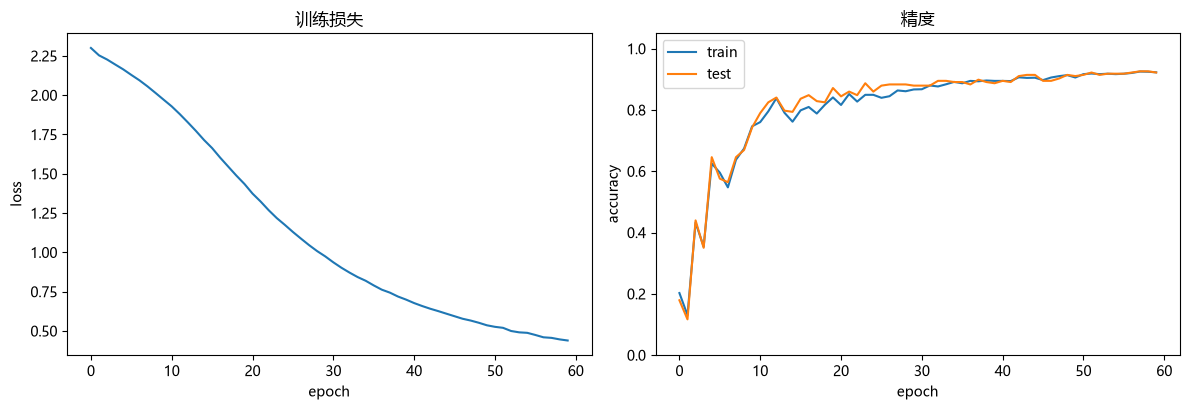

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.plot(history["loss"])
ax1.set_xlabel("epoch"); ax1.set_ylabel("loss"); ax1.set_title("训练损失")
ax2.plot(history["acc_train"], label="train")
ax2.plot(history["acc_test"], label="test")
ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy"); ax2.set_ylim(0, 1.05)
ax2.legend(); ax2.set_title("精度")
plt.tight_layout()
plt.show()

## 9.5 训练过程动画：把"学习"过程拍成电影

静态学习曲线只能看到结果。下面把训练过程**逐帧记录下来**，合成一个 GIF 动画：左边是损失和精度的实时变化，右边是一个固定测试样本的预测概率分布（从"均匀乱猜"慢慢收敛到"正确类别的概率接近 1"）和隐藏层权重模板的演变（从随机噪声慢慢长成有意义的笔画）。

实现思路：重新训练一遍（60 epoch），每 2 个 epoch 拍一帧快照（损失、精度、概率分布、W1），共 30 帧，再用 pillow 把它们拼成 GIF。



主角样本: 测试集第 5 张，真实标签 = 7


动画已保存: E:/item1：DeepLearningfromzero/train_animation.gif


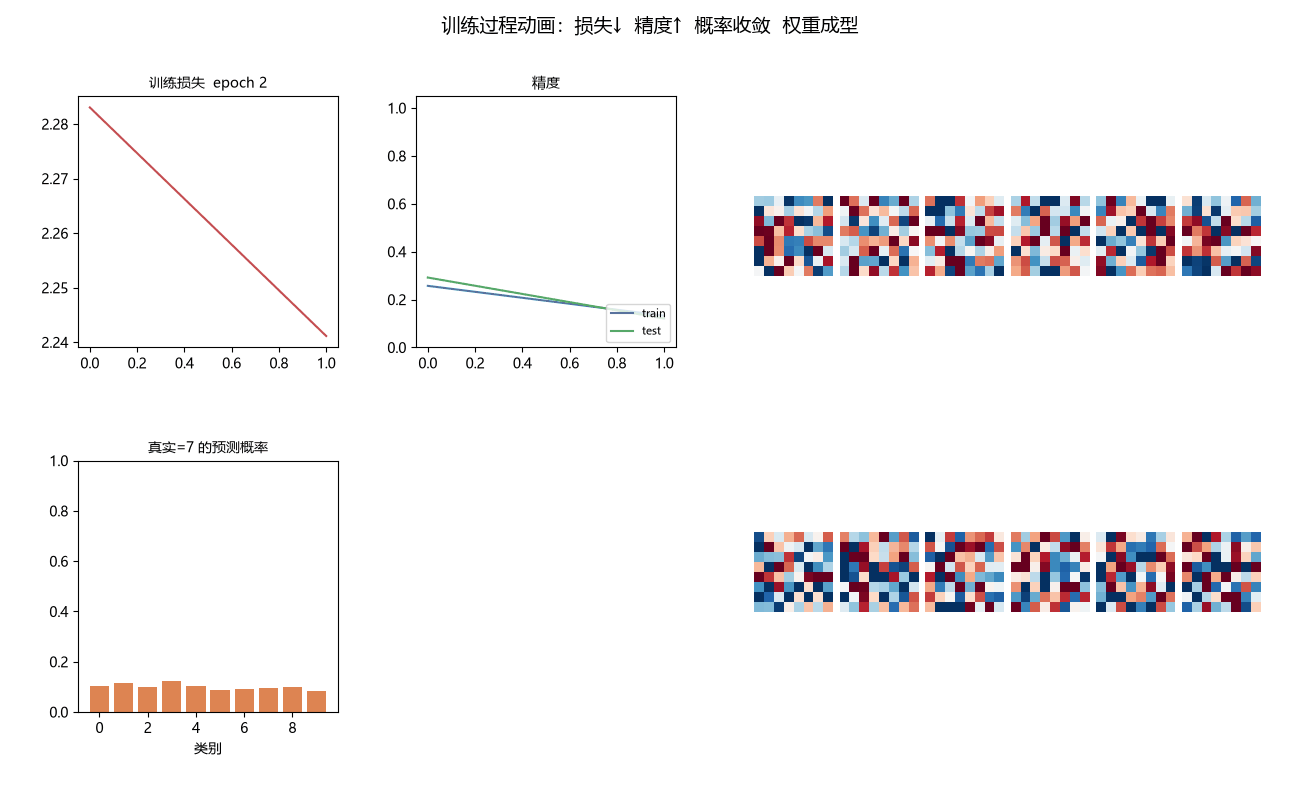

In [15]:
import os
from IPython.display import Image as IPImage
import matplotlib.animation as animation

# ---------- 训练并逐帧采样快照 ----------
def train_with_snapshots(X_train, T_train, X_test, T_test,
                         sample_idx=5, snap_every=2,
                         lr=0.1, epochs=60, batch_size=100, seed=42):
    """训练的同时，每 snap_every 个 epoch 记录一帧快照"""
    rng = np.random.default_rng(seed)
    n = X_train.shape[0]
    net_tmp = TwoLayerNet(input_size=64, hidden_size=50, output_size=10)
    history = {"loss": [], "acc_train": [], "acc_test": []}
    frames = []  # (epoch, 损失历史, 训练精度, 测试精度, 主角样本概率, W1 快照)
    for epoch in range(1, epochs + 1):
        perm = rng.permutation(n)
        X_shuf, T_shuf = X_train[perm], T_train[perm]
        losses = []
        for i in range(0, n, batch_size):
            x_b, t_b = X_shuf[i:i + batch_size], T_shuf[i:i + batch_size]
            grads = gradient(net_tmp, x_b, t_b)
            for key in net_tmp.params:
                net_tmp.params[key] -= lr * grads[key]
            losses.append(cross_entropy(net_tmp.forward(x_b), t_b))
        history["loss"].append(np.mean(losses))
        history["acc_train"].append(net_tmp.accuracy(X_train, T_train))
        history["acc_test"].append(net_tmp.accuracy(X_test, T_test))
        if epoch % snap_every == 0:
            prob = net_tmp.forward(X_test[sample_idx:sample_idx + 1])[0]
            frames.append((epoch, list(history["loss"]), list(history["acc_train"]),
                           list(history["acc_test"]), prob, net_tmp.params["W1"].copy()))
    return net_tmp, history, frames

# 挑一个测试样本当"主角"，看它的预测概率怎么从乱猜收敛到正确
sample_idx = 5
print("主角样本: 测试集第", sample_idx, "张，真实标签 =", y_test[sample_idx])
net_tmp, history2, frames = train_with_snapshots(X_train, T_train, X_test, T_test,
                                                 sample_idx=sample_idx)

# ---------- 逐帧绘制 ----------
fig = plt.figure(figsize=(13, 8))
fig.suptitle("训练过程动画：损失↓  精度↑  概率收敛  权重成型", fontsize=14)

gs_left = fig.add_gridspec(2, 2, left=0.06, right=0.52, wspace=0.30, hspace=0.45)
ax_loss = fig.add_subplot(gs_left[0, 0])
ax_acc  = fig.add_subplot(gs_left[0, 1])
ax_prob = fig.add_subplot(gs_left[1, 0])
gs_right = fig.add_gridspec(2, 6, left=0.58, right=0.97, wspace=0.08, hspace=0.20)
ax_ws = [fig.add_subplot(gs_right[i, j]) for i in range(2) for j in range(6)]

vmax_w = 0.15          # 权重颜色固定范围，避免不同帧颜色漂移
sample_label = int(y_test[sample_idx])

def update(fr):
    epoch, losses, accs_tr, accs_te, prob, W1s = fr
    ax_loss.clear(); ax_acc.clear(); ax_prob.clear()
    for axw in ax_ws:
        axw.clear()
    ax_loss.plot(losses, color="#C44E52")
    ax_loss.set_title(f"训练损失  epoch {epoch}", fontsize=10)
    ax_acc.plot(accs_tr, color="#4C72B0", label="train")
    ax_acc.plot(accs_te, color="#55A868", label="test")
    ax_acc.legend(loc="lower right", fontsize=8)
    ax_acc.set_ylim(0, 1.05); ax_acc.set_title("精度", fontsize=10)
    ax_prob.bar(range(10), prob, color="#DD8452")
    ax_prob.set_ylim(0, 1); ax_prob.set_xlabel("类别")
    ax_prob.set_title(f"真实={sample_label} 的预测概率", fontsize=10)
    for j, axw in enumerate(ax_ws):
        axw.imshow(W1s[:, j].reshape(8, 8), cmap="RdBu_r", vmin=-vmax_w, vmax=vmax_w)
        axw.axis("off")
    return []

anim = animation.FuncAnimation(fig, update, frames=frames, interval=100, repeat_delay=300)
gif_path = "E:/item1：DeepLearningfromzero/train_animation.gif"
anim.save(gif_path, writer="pillow", dpi=100)
plt.close(fig)
print("动画已保存:", gif_path)

# 在笔记本里直接展示 GIF
IPImage(filename=gif_path)

## 10. 测试集评估与预测可视化

用**从未参与训练**的测试集做最终评估，随机挑 15 张图展示预测结果（绿=对，红=错）。

测试集精度: 0.9222 (92.2%)


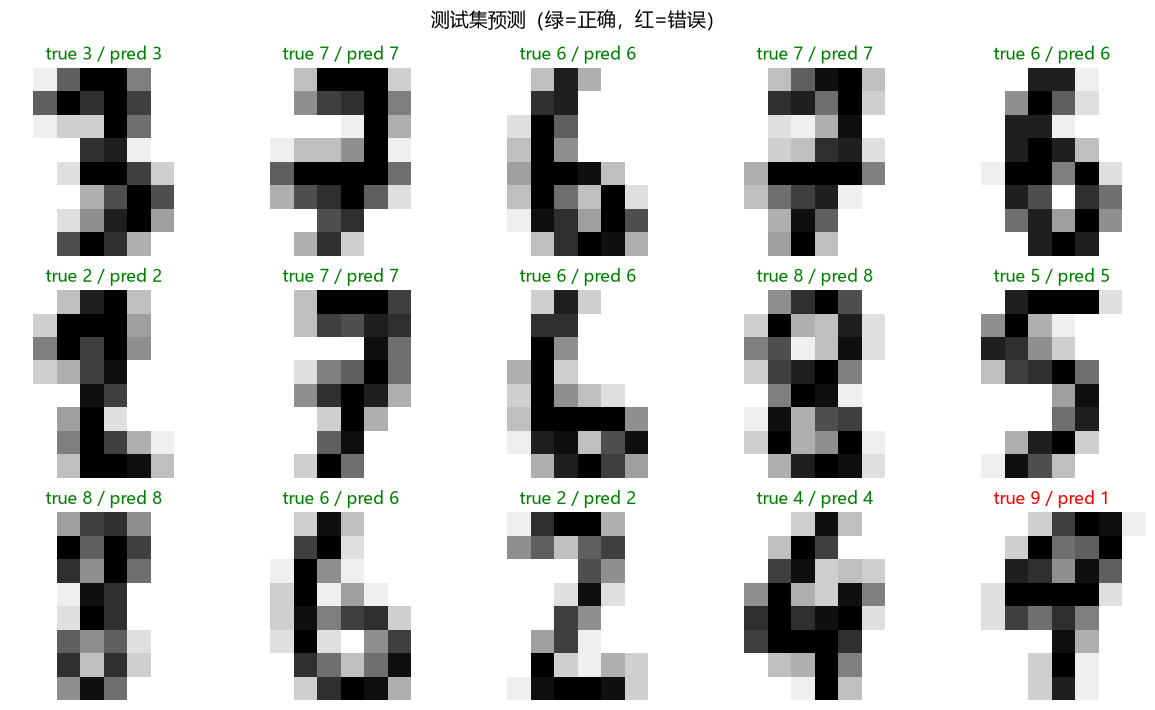

In [16]:
test_acc = net.accuracy(X_test, T_test)
print(f"测试集精度: {test_acc:.4f} ({test_acc * 100:.1f}%)")

y_pred = net.predict(X_test)
rng = np.random.default_rng(0)
show_idx = rng.choice(len(X_test), size=15, replace=False)

fig, axes = plt.subplots(3, 5, figsize=(12, 7.2))
for i, ax in zip(show_idx, axes.flat):
    ax.imshow(X_test[i].reshape(8, 8), cmap="gray_r")
    ok = y_pred[i] == y_test[i]
    ax.set_title(f"true {y_test[i]} / pred {y_pred[i]}", color=("green" if ok else "red"))
    ax.axis("off")
plt.suptitle("测试集预测（绿=正确，红=错误）", fontsize=14)
plt.tight_layout()
plt.show()

只看一个精度数字还不够：**混淆矩阵**能看到"哪些数字容易互相认错"。第 $t$ 行第 $p$ 列 = 真实是 $t$ 却被预测成 $p$ 的样本数，对角线就是预测正确的部分。

对角线上的数字越大，说明认对的越多；对角线上下的亮点，就是"把 3 看成 8"这类长得像的数字在互相串门。

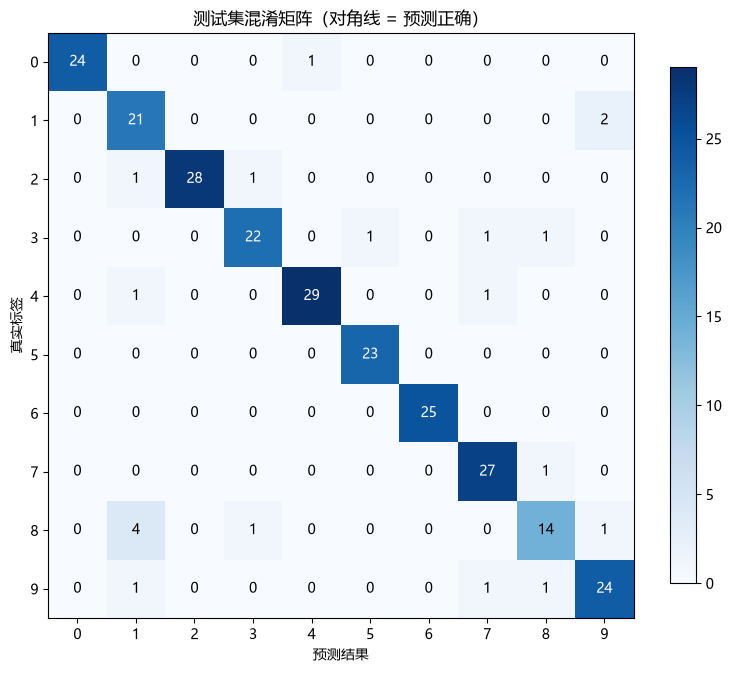

各数字认错率（从高到低）:
  数字 8: 30%（6 张认错 / 共 20 张）
  数字 3: 12%（3 张认错 / 共 25 张）
  数字 9: 11%（3 张认错 / 共 27 张）
  数字 1: 9%（2 张认错 / 共 23 张）
  数字 2: 7%（2 张认错 / 共 30 张）
  数字 4: 6%（2 张认错 / 共 31 张）
  数字 0: 4%（1 张认错 / 共 25 张）
  数字 7: 4%（1 张认错 / 共 28 张）


In [17]:
# 手动算混淆矩阵（不依赖额外库）
cm = np.zeros((10, 10), dtype=int)
for t, p in zip(y_test, y_pred):
    cm[t, p] += 1

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("预测结果"); ax.set_ylabel("真实标签")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.title("测试集混淆矩阵（对角线 = 预测正确）")
plt.tight_layout()
plt.show()

# 顺便算一下：哪个数字最容易认错
total_per_digit = cm.sum(axis=1)
wrong_per_digit = total_per_digit - np.diag(cm)
err_rate = wrong_per_digit / total_per_digit
print("各数字认错率（从高到低）:")
for k in np.argsort(-err_rate):
    if err_rate[k] > 0:
        print(f"  数字 {k}: {err_rate[k]:.0%}（{wrong_per_digit[k]} 张认错 / 共 {total_per_digit[k]} 张）")

再把这些被认错的样本挑出来看看：到底是"长得太像"，还是模型的问题。

测试集共认错 20 张（展示前 10 张）


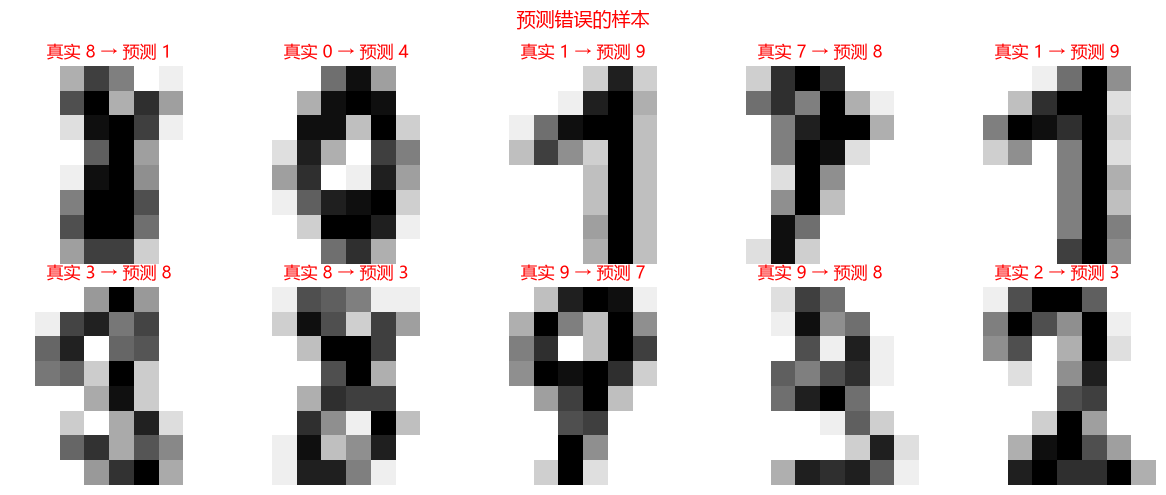

In [18]:
wrong_idx = np.where(y_pred != y_test)[0]
n_show = min(10, len(wrong_idx))
print(f"测试集共认错 {len(wrong_idx)} 张（展示前 {n_show} 张）")

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    if i >= n_show:
        ax.axis("off")
        continue
    idx = wrong_idx[i]
    ax.imshow(X_test[idx].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"真实 {y_test[idx]} → 预测 {y_pred[idx]}", color="red")
    ax.axis("off")
plt.suptitle("预测错误的样本", fontsize=14, color="red")
plt.tight_layout()
plt.show()

## 11. 第一层权重可视化：网络学到了什么

把 $W_1$（64×50）的每一列画成一张 8×8 小图，共 50 张，就是 50 个隐藏神经元学到的"笔画模板"。高亮的红色区域表示该神经元对那里的像素"敏感"——这是特征学习最直观的证据。

每个小图 = 一个隐藏神经元"爱看的笔画"：红色亮的地方，说明它对那几块像素特别敏感。学完再看，你会发现它们真的长出了横、竖、圈之类的形状——网络不是瞎猜，是真的"看懂了笔画的构成"。

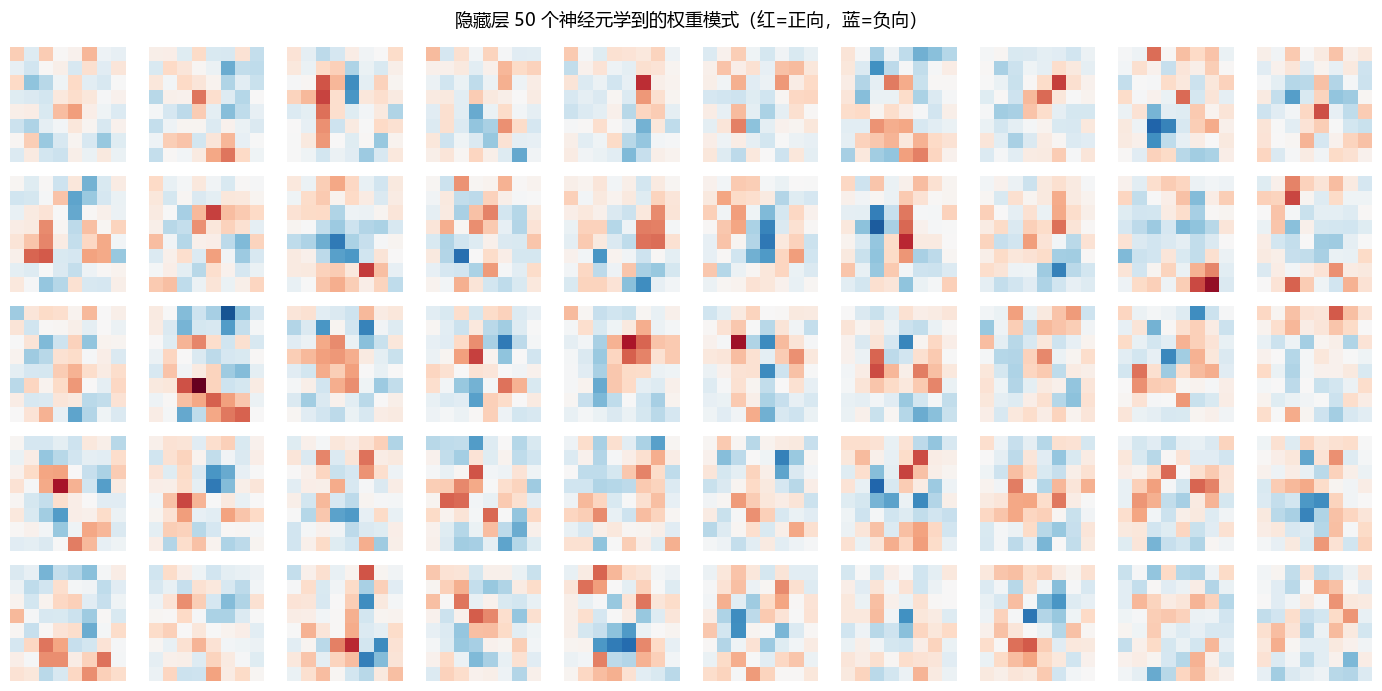

In [19]:
W1 = net.params["W1"]   # (64, 50)，每个隐藏神经元对应一列
vmax = np.abs(W1).max()
fig, axes = plt.subplots(5, 10, figsize=(14, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(W1[:, i].reshape(8, 8), cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.axis("off")
plt.suptitle("隐藏层 50 个神经元学到的权重模式（红=正向，蓝=负向）", fontsize=13)
plt.tight_layout()
plt.show()

## 12. 总结与扩展练习

### 我们做了什么

没有调用任何深度学习框架，仅用 `numpy` 实现了：64→50→10 的两层网络、sigmoid/softmax、交叉熵损失、反向传播（并用数值梯度验证正确）、mini-batch SGD，最终在手写数字测试集上达到 **92% 左右**的精度。

整个流程我们把它可视化了出来：网络结构 → 激活函数曲线 → 交叉熵损失曲线 → 学习曲线 → 测试集预测 → 混淆矩阵 → 第一层权重模式。现在你应该能"看见"每一步在做什么了。

### 用来自测的问题

1. 为什么权重必须**随机初始化**？全 0 初始化会发生什么？
2. 为什么 softmax + 交叉熵组合的输出层梯度是简洁的 $y - t$？
3. 数值梯度与解析梯度为什么应该一致？数值梯度为什么不能用于正式训练？
4. 学习率 $\eta$ 太大 / 太小分别会有什么现象？试着改成 1.0 和 0.001 观察损失曲线。

### 可以怎么玩

- 把隐藏层换成 **ReLU**（$\max(0, z)$），或加深一层（三层网络），观察精度变化；
- 把 `weight_init_std` 改回 **0.01** 重新训练，对比学习速度——感受"初始值设定"对 sigmoid 网络的影响；
- 换成真正的 **MNIST**（28×28、7 万张），只需替换"数据准备"那一节；
- 加 **L2 正则** 或 **Dropout**，看能否抑制过拟合；
- 试试不同的 batch_size、隐层宽度，观察学习曲线形状的变化；
- 给混淆矩阵加一列"最容易混淆的数字对"，看看 8 和 3、5 和 6 是不是冤家。

把整个实验说成人话：喂它 1540 张带答案的手写数字图 → 它用随机的"出厂设置"瞎猜 → 猜一次得一个损失（扣分）→ 用反向传播算出每个旋钮该往哪拧 → 按学习率拧一圈（一个 epoch）→ 翻来覆去拧 60 圈 → 拿 257 张从没见过的图考它，92.2 分。从头到尾你没有用任何现成框架，"拧旋钮"的动作全是你用 numpy 亲手实现的。

恭喜，到这里你已经拥有一个"从零实现"的神经网络了！